# A single section with HEBI

One Xenium section of human breast cancer, encoded, clustered into niches,
and read for regulatory structure.

This is the smallest complete run: one slide in, representations, niches
and a gene-attention analysis out. Notebook 03 does the same thing over
three serial sections at once; start here, and go there when you have
more than one slide you want to compare.

**What one section gives you, and what it does not.** Everything HEBI
produces here is defined by this run. The prototypes are shared across
cells within the section, so a niche label means the same thing in every
part of this slide. It does not carry to another slide encoded in a
separate run: niche 4 here and niche 4 in a second run are two unrelated
groups that happen to share a number. The sample used below has a second
replicate, and the way to compare the two is to encode them together, not
to run this notebook twice.

The work is split into three stages, because they cost very different
amounts:

| stage | what it does | cost |
| --- | --- | --- |
| **encode** | adapt the model, run it over every cell | minutes to hours |
| **cluster** | group the resulting representations | seconds |
| **GRN** | what the learned gene attention says | minutes |

Keeping them separate means trying a different number of clusters does
not re-encode anything.

**Runtime.** This section holds on the order of 10^5 cells, several times
a STARmap section, and both preprocessing and encoding scale with that.
Budget roughly an hour on a single GPU for the whole notebook, most of it
the METIS partition and the ten adaptation epochs.

**The data.** Replicate 1 of the 10x Genomics Xenium human breast cancer
sample from Janesick et al. (2023), a 313-gene panel on an FFPE section.
The section is available from
[10x Genomics](https://www.10xgenomics.com/products/xenium-in-situ/preview-dataset-human-breast)
and from GEO under GSE243275. The published per-cell type annotation ships
separately as `Cell_Barcode_Type_Matrices.xlsx`; it is optional, and is
used here only to score the result, never to produce it.

## 1. Setup

Edit these four paths. Everything else follows from them.

In [2]:
from pathlib import Path

# --- edit these -------------------------------------------------------
DATA_DIR   = Path("/DATA1/Roxana/Data")
VOCAB_PATH = Path("/DATA1/Roxana/Hierarchy/Two_levels/default_gene_vocab.json")
CHECKPOINT = Path("/DATA1/Roxana/hebi_repo/notebooks/hebi_hybrid_oldL0.pt")
WORK_DIR   = Path("./breast_tutorial")
# ----------------------------------------------------------------------

LABEL = "rep1"
STEM  = "Xenium_bc/xenium_breast_cancer_rep1"

H5AD_FILE = DATA_DIR / f"{STEM}.h5ad"

# The pipeline takes lists throughout, so that one section and twenty
# sections go through the same code. A single section is a list of one,
# and every downstream list keeps that shape.
H5AD_FILES = [H5AD_FILE]
LABELS     = [LABEL]

PROCESSED_DIR = WORK_DIR / "processed"
RESULTS_DIR   = WORK_DIR / "results"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Used only for scoring. Set to None if your section is unannotated;
# everything still runs and FIDE is reported instead of ARI and NMI.
ANNOTATION = "annotation"

# Xenium exports usually carry raw counts in X and keep no layers.
COUNTS_LAYER = None

print(f"{'found  ' if H5AD_FILE.exists() else 'MISSING'} {H5AD_FILE.name}")

found   xenium_breast_cancer_rep1.h5ad


## 2. What is in the data

HEBI needs two things from an `.h5ad`: an expression matrix, and spatial
coordinates in `obsm`. Everything else is optional.

Worth checking before anything else is what the matrix actually holds.
Preprocessing decides what to apply from the state it finds, so it helps
to know what that state is.

In [3]:
import numpy as np
import scanpy as sc

adata = sc.read_h5ad(H5AD_FILE)
print(adata)
print()
print("spatial coordinates:", [k for k in adata.obsm])
print("layers:             ", [k for k in adata.layers] or "none")
adata = adata[adata.obs[ANNOTATION] != "Unlabeled"].copy()
if ANNOTATION:
    print("annotated types:    ", adata.obs[ANNOTATION].nunique())

block = adata.X[:500]
block = block.toarray() if hasattr(block, "toarray") else np.asarray(block)
integral = np.allclose(block, np.round(block))
print("X:                  ",
      "raw counts" if integral else "already transformed",
      f"(max {block.max():.2f}, median library size "
      f"{np.median(block.sum(axis=1)):.0f})")
del adata, block

AnnData object with n_obs × n_vars = 159226 × 313
    obs: 'x_centroid', 'y_centroid', 'annotation'
    var: 'gene_ids', 'feature_types', 'genome'
    obsm: 'spatial'

spatial coordinates: ['spatial']
layers:              none
annotated types:     19
X:                   raw counts (max 59.00, median library size 136)


Xenium counts per cell are low, typically a couple of hundred transcripts
over a few hundred panel genes. That is worth keeping in mind at the
normalisation step below, where rescaling every cell to a fixed library
size is a much larger intervention here than it would be on
whole-transcriptome data.

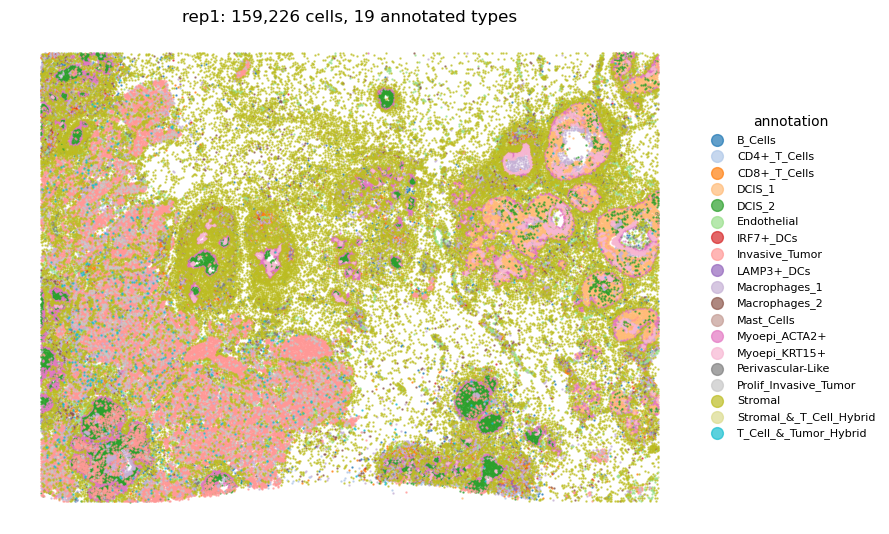

In [4]:
import matplotlib.pyplot as plt

adata = sc.read_h5ad(H5AD_FILE)
coords = np.asarray(adata.obsm["spatial"])[:, :2]

fig, ax = plt.subplots(figsize=(9, 8))
if ANNOTATION:
    groups = adata.obs[ANNOTATION].astype("category")
    cmap = plt.get_cmap("tab20")
    for i, name in enumerate(groups.cat.categories):
        m = (groups == name).to_numpy()
        ax.scatter(coords[m, 0], coords[m, 1], color=cmap(i % 20),
                   s=0.5, alpha=0.7, rasterized=True, label=name)
    ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5),
              frameon=False, markerscale=12, fontsize=8, title=ANNOTATION)
    title = f"{groups.nunique()} annotated types"
else:
    counts = np.asarray(adata.X.sum(axis=1)).ravel()
    pts = ax.scatter(coords[:, 0], coords[:, 1], c=counts, cmap="viridis",
                     s=0.5, alpha=0.7, rasterized=True)
    fig.colorbar(pts, ax=ax, shrink=0.6, label="total counts")
    title = "total counts"

ax.set_title(f"{LABEL}: {adata.n_obs:,} cells, {title}")
ax.set_aspect("equal")
ax.axis("off")
plt.tight_layout()
plt.show()
del adata

## 3. Choosing the graph neighbourhood

Each cell is connected to its `k` nearest spatial neighbours, and `k`
controls how much of the surroundings enters that cell's representation.

`k` is a count, but what matters is the physical distance it covers, and
that depends on how densely the tissue is sampled. The same `k` spans a
very different area on a dense section than on a sparse one. So rather
than copying a number, measure the reach first.

The reach is the distance to the k-th neighbour expressed in cell
diameters, where one diameter is roughly the spacing between touching
cells. It is computed from coordinates alone, with no annotations, so `k`
is never selected against the labels the result will later be scored
against.

In [5]:
from hebi.data.graph_diagnostics import (
    neighbour_diagnostics, suggest_k, report, _find_spatial
)

adata = sc.read_h5ad(H5AD_FILE)
rows, scale = neighbour_diagnostics(_find_spatial(adata), n_sample=20000)
report(rows, scale, suggest_k(rows), name=LABEL)
del adata

  159,226 cells; querying 20,000 of them up to k=100

  median nearest-neighbour distance: 9.544
  implied cell diameter:             19.088

      k       reach   diameters
  -----------------------------
      3       12.83        0.67
      5       15.88        0.83
     10       22.39        1.17
     15       27.46        1.44
     20       31.74        1.66
     30       39.06        2.05
     40       45.24        2.37
     50       50.73        2.66
     75       62.53        3.28
    100       72.63        3.81

  suggested k: 30 to 50   (2.05 to 2.66 cell diameters)
  target is 2.0 to 3.0 diameters: a cell plus its first two rings of contacts.

  For reference, the sections HEBI was developed on:
    platform   tissue            NN dist    k   reach
    Xenium     human breast         9.54   30    2.05
    MERSCOPE   human breast         7.71   30    2.28
    CosMx      human liver           n/a   30    2.42
    STARmap    mouse CNS           41.27   30    3.21
  This is a st

Two to three cell diameters covers a cell and its first two rings of
contacts, which is a reasonable starting range.

`k=30` is used here. Xenium segments single cells at high density, so 30
neighbours stays within that range and describes a genuinely local
neighbourhood. On a sparser platform the same 30 would reach much
further, which is the reason for measuring rather than copying.

In [6]:
K_NEIGHBORS = 30

## 4. Preprocessing

The `.h5ad` becomes a `.pt` section holding the expression matrix on the
shared gene vocabulary, the spatial graph, the METIS partition, and
metadata describing how it was built.

Two things happen here worth knowing about.

**Gene harmonisation.** The section is projected onto one fixed
vocabulary, so sections with different panels end up in a common feature
space. Genes outside the vocabulary are dropped and the coverage is
printed. On a targeted panel the number of retained genes will be in the
hundreds, not the thousands. That is the panel, not a failure: the model
reads whichever vocabulary positions this section measures.

**Normalisation is detected, not assumed.** Applying `log1p` to data that
has already been logged produces values that look plausible and are
wrong, and nothing downstream can detect it. So the state of the matrix
is reported and `log1p` is applied only when missing. Library-size
normalisation is a separate, explicit choice, off unless asked for
(`--normalise` on the command line). On low-count panel data it is a
strong rescaling, so it is worth making deliberately rather than by
default.

In [7]:
from hebi.data.preprocess import preprocess_h5ad

# Preprocessing is the slow part, mostly METIS, so it is skipped when the
# output already exists. Set this True after changing k, the counts
# layer, or normalisation.
OVERWRITE = False

produced = preprocess_h5ad(
    h5ad_path=H5AD_FILE,
    out_root=PROCESSED_DIR,
    vocab_path=VOCAB_PATH,
    task="clustering",
    k=K_NEIGHBORS,
    min_counts=40,
    species="Human",
    counts_layer=COUNTS_LAYER,
    overwrite=OVERWRITE,
)
section_files = [p.name for p in produced]

print("\nsection ready:")
for name in section_files:
    print(" ", name)

/home/tower4/miniconda3/envs/hebi/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



Loading xenium_breast_cancer_rep1.h5ad
  metadata: {'species': 'Unknown', 'tissue': 'Breast', 'disease': 'Diseased'}
  filter_cells(min_counts=40): 159226 -> 152449 cells
Covered genes: 302/313 (96.49%)
  [xenium_breast_cancer_rep1] data status: raw_counts
           all values integral, max 99 — raw counts
           applied: log1p
           library size NOT corrected. Pass --normalise to apply normalize_total before log1p.
  152,449 cells; querying 20,000 of them up to k=75
  [xenium_breast_cancer_rep1] k=30 spans 2.03 cell diameters (median nearest-neighbour distance 9.75)
🔧 Building 30-NN spatial graph (coords=(152449, 2)) ...
✅ Graph built: 152449 nodes, 5061326 edges
🔧 [METIS] Creating NetworkX graph for 152449 nodes...
🔧 [METIS] Running METIS partitioning to create 1024 partitions...
✅ [METIS] METIS partitioning complete.
🔧 [METIS] Computing super-graph adjacency...
🔧 [METIS] Computing super-graph shortest paths...
✅ [METIS] Fixed partition and distance matrix created.
  saved

The `.pt` records how it was built. Read this back before reusing a
section from an earlier run: `k_neighbors` and `normalisation_state`
decide whether it is comparable with anything else you have, and
`reach_cell_diameters` says what that `k` meant physically for this
tissue.

In [8]:
import torch

meta = torch.load(PROCESSED_DIR / section_files[0],
                  map_location="cpu", weights_only=False)["meta"]
for key, value in meta.items():
    print(f"  {key:<28} {value}")

  species                      Human
  tissue                       Breast
  disease                      Diseased
  normalisation_on_input       raw_counts
  normalisation_applied        ['log1p']
  normalisation_state          log_transformed
  k_neighbors                  30
  n_metis_clusters             1024
  seed                         42
  reach_cell_diameters         2.03


## 5. Stage one: encoding

This is the expensive stage and the only one that touches the model.

**Mode.** `zero_shot` encodes with frozen weights. `continual` first
adapts for a few epochs on this section, using exactly the
self-supervised objective from pretraining, then encodes. The two share
the same encoding procedure; they differ only in whether a short
adaptation precedes it.

**Initialisation.** `pretrained` loads the foundation weights and is the
intended way to run the model on a new section. `random` starts from
scratch, the baseline that shares the architecture but not the pretrained
knowledge. `hybrid` randomises only the cell-level encoder. One caution
if you intend to report numbers: if the section you are running was part
of the pretraining corpus, a `pretrained` score on it is contaminated and
means nothing as a benchmark. Check what the checkpoint saw before
quoting a result.

**What comes out.** Three representations per cell, written into
`adata.obsm` as `z0`, `z1`, `z2`, plus the prototype assignment in
`adata.obs["prototypes"]`. That last one is not a clustering: it is the
Level-2 attention argmax, read straight from the forward pass.

`grn=True` also builds the gene-interaction graph and trains the
refinement layer during adaptation, which stage three needs. It requires
`mode="continual"`: in zero-shot the layer is never trained, so its
attention would carry no signal.

The AnnData is normalised in memory before encoding, because the GRN
stage reads expression from it. Pass `preprocess=False` if your file is
already normalised and logged.

In [9]:
#Zero_shot
from hebi.inference.pipeline import encode_sections

sections, ctx = encode_sections(
    checkpoint_path=str(CHECKPOINT),
    data_dir=str(PROCESSED_DIR),
    section_files=section_files,
    h5ad_files=[str(p) for p in H5AD_FILES],
    vocab_path=str(VOCAB_PATH),
    section_labels=LABELS,

    mode="zero_shot",
    init="pretrained",
    num_epochs=10,
    lr=1e-4,

    grn=False,
    species="Human",

    output_dir=str(RESULTS_DIR),
    seed=2025,
)

Seed set to 2025
Loading /DATA1/Roxana/Data/Xenium_bc/xenium_breast_cancer_rep1.h5ad
Covered genes: 302/313 (96.49%)
  159226 cells, 302 genes
  xenium_breast_cancer_rep1.pt: 159226 -> 152449 cells matched to the .pt by coordinate
🎲 Seed set to 0
--- Using device: cuda:0 ---
📁 Found 2 slides in breast_tutorial/processed
📦 Loading preprocessed slide from breast_tutorial/processed/Xenium_breast_cancer_rep1_harmonised1.pt
✅ Loaded data: X=torch.Size([152449, 302]), coords=torch.Size([152449, 2]), edge_index=torch.Size([2, 5061326])
🔧 Initializing models...
  -> Using L0 Encoder: LocalTransformerEncoder
🔧 Initializing optimizer...
Loaded checkpoint /DATA1/Roxana/hebi_repo/notebooks/hebi_hybrid_oldL0.pt (epoch 50)

Encoding 1 section(s)
📦 Loading preprocessed slide from breast_tutorial/processed/xenium_breast_cancer_rep1.pt
✅ Loaded data: X=torch.Size([152449, 302]), coords=torch.Size([152449, 2]), edge_index=torch.Size([2, 5061326])


Encoding breast_tutorial/processed/xenium_breast_cancer_rep1.pt: 100%|█| 75/75 [


  152,449 cells encoded; 1/20 prototypes in use


In [10]:
adata = sections[0]
print("representations:", [k for k in adata.obsm if k.startswith("z")])
print("prototypes:     ", adata.obs["prototypes"].nunique(), "in use")
print()
print(adata.obsm["z0"].shape, "cell-level embedding")

representations: ['z0', 'z1', 'z2']
prototypes:      1 in use

(152449, 128) cell-level embedding


## 6. Stage two: clustering

Two clusterings, both fitted over the whole section at once.

**Cell level** clusters `z0`, the representation of a cell in the context
of its immediate spatial neighbourhood.

**Niche level** clusters each cell's local prototype composition: take
its `composition_neighbors` nearest neighbours, count which prototypes
they carry, and cluster those vectors. Cells in the same kind of
microenvironment get similar vectors regardless of which single prototype
they happen to fall on.

Labels are named after the setting that produced them, so several
clusterings coexist and their figures do not overwrite each other.

In [11]:
from hebi.inference.pipeline import cluster_sections

written = cluster_sections(
    sections, ctx,
    n_cell_clusters=18,
    n_composition_niches=14,
    composition_neighbors=200,
    cluster_method="kmeans",
    cell_type_key=ANNOTATION,
    niche_key=ANNOTATION,
    point_size=2,
)
print("\nwritten:", written)


Cell-level clustering: kmeans, k=18  ->  obs['z0_kmeans_18']
Niche-level clustering: 14 niches from 200-neighbour composition  ->  obs['comp_niches_14']

rep1
  z0_kmeans_18           ARI=0.2867  NMI=0.5290  FIDE=0.3625
  FIDE degenerate: 1 unique label — returning 0.0
  prototypes             ARI=0.0000  NMI=0.0000  FIDE=0.0000
  FIDE degenerate: 1 unique label — returning 0.0
  comp_niches_14         ARI=0.0000  NMI=0.0000  FIDE=0.0000

  Saved z0_kmeans_18 (s=2.0)
  Saved comp_niches_14 (s=2.0)

written: {'cell_clusters': 'z0_kmeans_18', 'composition_niches': 'comp_niches_14'}


### Reading the scores

**ARI** and **NMI** compare labels against the annotation, and are only
meaningful where one exists.

**FIDE** is the fraction of spatial edges joining cells with the same
label, weighted down when few labels are used. It measures spatial
contiguity and needs no annotation, which makes it the one to watch on
unannotated tissue.

Expect `prototypes` to score lower than the other two. It is the raw
per-cell attention argmax before any spatial aggregation, so it is
scattered by construction; the composition step is what turns it into
coherent niches.

One thing not to over-read: cell-level clusters are scored here against a
cell-type annotation, but they are not cell types. `z0` describes a cell
in its neighbourhood, so a tumour cell at an immune boundary and one deep
inside a tumour nest can land in different clusters while carrying the
same annotation. A moderate ARI can mean the clustering is picking up
spatial context the annotation does not record.

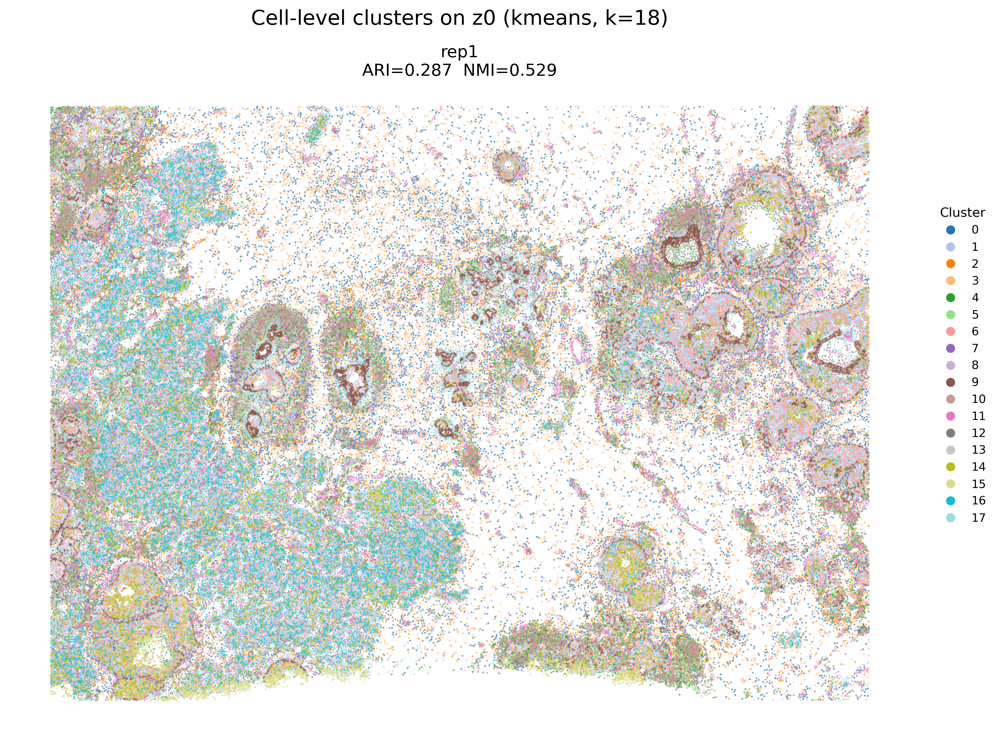

In [12]:
from IPython.display import Image, display

display(Image(filename=str(RESULTS_DIR / f"{written['cell_clusters']}.png")))

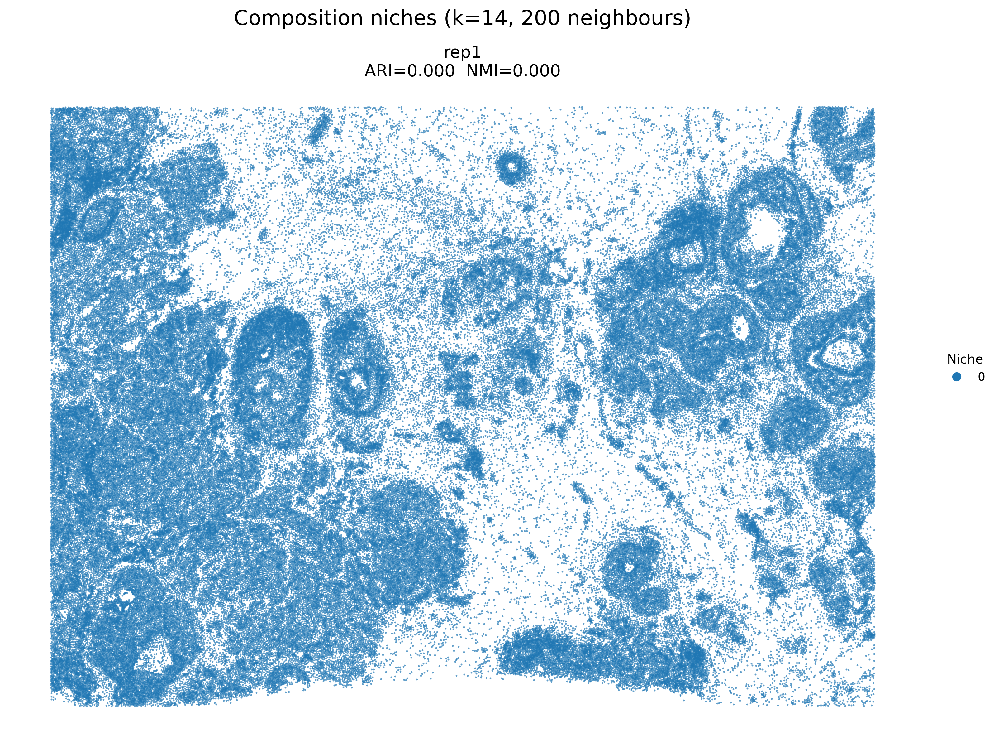

In [13]:
display(Image(filename=str(RESULTS_DIR / f"{written['composition_niches']}.png")))

key: prototypes


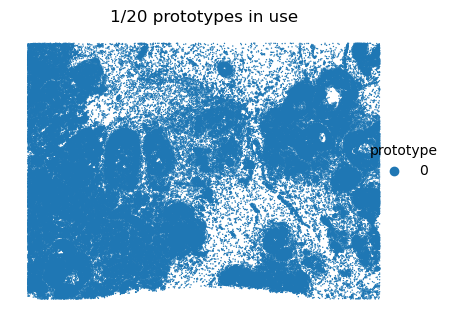

prototypes
0    152449
Name: count, dtype: int64


In [14]:
import matplotlib.pyplot as plt
import numpy as np

key = [k for k in sections[0].obs if "proto" in k][0]          # ستون prototype
print("key:", key)
allp = np.unique(np.concatenate([a.obs[key].astype(str) for a in sections]))
cmap = plt.get_cmap("tab20")
col = {p: cmap(i % 20) for i, p in enumerate(allp)}             # رنگ یکسان در همه‌ی sectionها

fig, axes = plt.subplots(1, len(sections), figsize=(5 * len(sections), 5), squeeze=False)
for ax, a in zip(axes[0], sections):
    xy = a.obsm["spatial"]; lab = a.obs[key].astype(str).to_numpy()
    ax.scatter(xy[:, 0], xy[:, 1], c=[col[l] for l in lab], s=1, linewidths=0)
    u, c = np.unique(lab, return_counts=True)
    ax.set_title(f"{len(u)}/20 prototypes in use"); ax.set_aspect("equal"); ax.axis("off")
handles = [plt.Line2D([], [], marker="o", ls="", color=col[p], label=p) for p in allp]
fig.legend(handles=handles, title="prototype", loc="center right", frameon=False)
plt.show()
for a in sections:
    print(a.obs[key].value_counts().head(5))

### Trying other numbers

Because encoding already happened, changing the cluster count costs
seconds. Each call writes new columns and new figures rather than
replacing the old ones, so results can be compared side by side.

In [ ]:
written_24 = cluster_sections(
    sections, ctx,
    n_cell_clusters=24,
    n_composition_niches=8,
    composition_neighbors=200,
    cell_type_key=ANNOTATION,
    niche_key=ANNOTATION,
    point_size=2,
)
print("\nwritten:", written_24)
print()
print("all clusterings now on the object:")
for col in sections[0].obs.columns:
    if col.startswith(("z0_", "comp_niches_", "prototypes")):
        print("  ", col)

In [46]:
#Continual
from hebi.inference.pipeline import encode_sections

sections, ctx = encode_sections(
    checkpoint_path=str(CHECKPOINT),
    data_dir=str(PROCESSED_DIR),
    section_files=section_files,
    h5ad_files=[str(p) for p in H5AD_FILES],
    vocab_path=str(VOCAB_PATH),
    section_labels=LABELS,

    mode="continual",
    init="random",
    num_epochs=15,
    lr=1e-4,

    grn=True,
    species="Human",

    output_dir=str(RESULTS_DIR),
    seed=789,
)

Seed set to 789
Loading /DATA1/Roxana/Data/Xenium_bc/xenium_breast_cancer_rep1.h5ad
Covered genes: 302/313 (96.49%)
  159226 cells, 302 genes
  xenium_breast_cancer_rep1.pt: 159226 -> 152449 cells matched to the .pt by coordinate

Building gene-interaction graph
🧬 Building directed heterogeneous GRN (Species: Human)...
   Fetching curated priors (Pathway, LigRec, TF-Target)...
   Fetching 'pathwayextra' from OmniPath web API (whole dataset)...
   [cache-write] updated local cache for 'pathwayextra': 48764 rows
   Fetching 'ligrecextra' from OmniPath web API (whole dataset)...
   [cache-write] updated local cache for 'ligrecextra': 6658 rows
   Fetching 'dorothea' from OmniPath web API (whole dataset)...
   [cache-write] updated local cache for 'dorothea': 15267 rows
   Computing data-driven Spearman edges...
   [info] input already log-scale (max=8.33) -- skipping normalize_total/log1p to avoid double-normalizing
   Constructing PyG graph with directed edge typing...
✅ Directed GRN bui

Encoding breast_tutorial/processed/xenium_breast_cancer_rep1.pt: 100%|█| 75/75 [


  152,449 cells encoded; 13/20 prototypes in use


In [47]:
from hebi.inference.pipeline import cluster_sections

written = cluster_sections(
    sections, ctx,
    n_cell_clusters=18,
    n_composition_niches=14,
    composition_neighbors=200,
    cluster_method="kmeans",
    cell_type_key=ANNOTATION,
    niche_key=ANNOTATION,
    point_size=2,
)
print("\nwritten:", written)


Cell-level clustering: kmeans, k=18  ->  obs['z0_kmeans_18']
Niche-level clustering: 14 niches from 200-neighbour composition  ->  obs['comp_niches_14']

rep1
  z0_kmeans_18           ARI=0.1800  NMI=0.3485  FIDE=0.6238
  prototypes             ARI=0.2175  NMI=0.3056  FIDE=0.9018
  comp_niches_14         ARI=0.1319  NMI=0.2234  FIDE=0.9073

  Saved z0_kmeans_18 (s=2.0)
  Saved comp_niches_14 (s=2.0)

written: {'cell_clusters': 'z0_kmeans_18', 'composition_niches': 'comp_niches_14'}


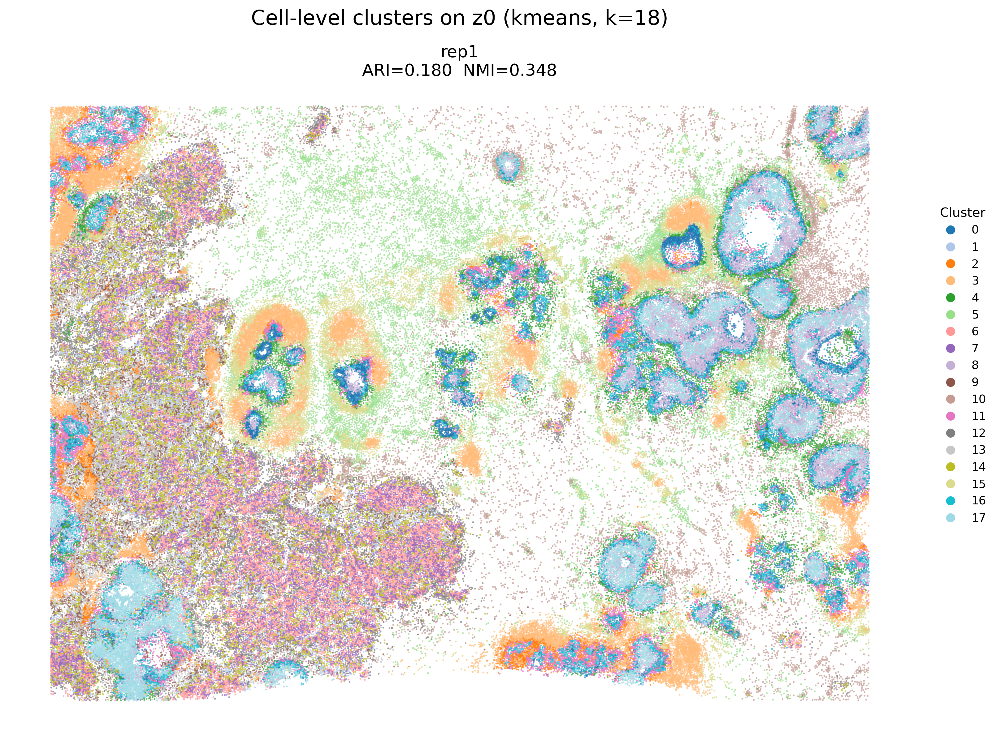

In [48]:
from IPython.display import Image, display

display(Image(filename=str(RESULTS_DIR / f"{written['cell_clusters']}.png")))

prototypes 13 prototypes in use


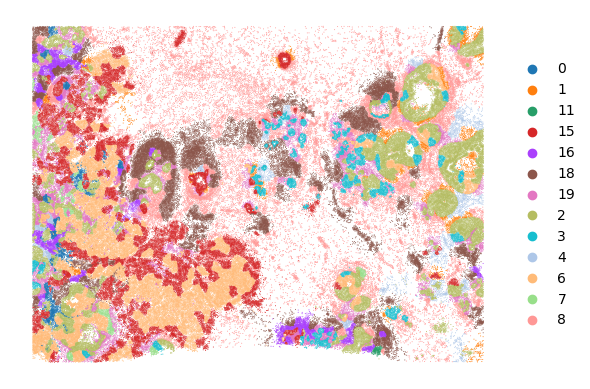

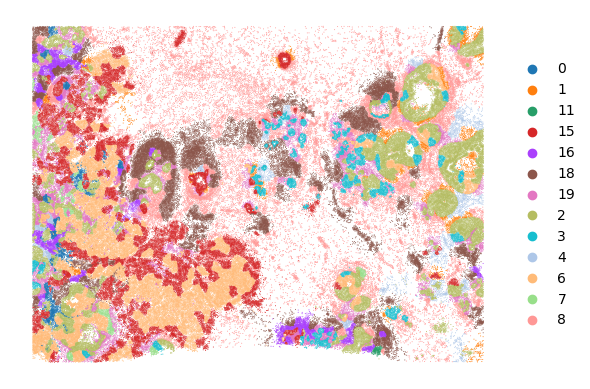

In [60]:
import scanpy as sc
import matplotlib.pyplot as plt
from IPython.display import Image, display
%matplotlib inline

ad = sections[0]
proto_key = [k for k in ad.obs if "proto" in k][0]      # e.g. 'prototypes'
ad.obs[proto_key] = ad.obs[proto_key].astype(str).astype("category")
print(proto_key, ad.obs[proto_key].nunique(), "prototypes in use")
sc.pl.embedding(ad, basis="spatial", color=proto_key, s=2,
                frameon=False, title="", show=False)
out = RESULTS_DIR / f"{proto_key}.png"
plt.savefig(out, dpi=300, bbox_inches="tight")
plt.savefig(out.with_suffix(".svg"), bbox_inches="tight")
plt.show()

One caution. Choosing the number of clusters by whichever gives the
highest ARI means selecting on the signal you then report, which
overstates performance. Use the annotation to sanity-check that the
labels are sensible, and choose the number from what you expect to
resolve.

`composition_neighbors` is worth varying too. It sets how much
surrounding tissue defines a niche, and like `k` it is a count standing
in for a distance. On a dense Xenium section 200 neighbours covers a
small physical area; on a sparse section the same number reaches across
a structure.

### What is in each niche?

A niche is a mixture, not a cell type. The check that it is behaving is
that each niche is a recognisable combination rather than a single label,
and that the combinations differ from each other.

In [61]:
import pandas as pd

adata = sections[0]
niche_col = "prototypes"

if ANNOTATION:
    frac = pd.crosstab(adata.obs[niche_col], adata.obs[ANNOTATION],
                       normalize="index")
    sizes = adata.obs[niche_col].value_counts()
    print(f"Composition of each {niche_col}, top three contributors:\n")
    for niche in frac.index:
        top = frac.loc[niche].sort_values(ascending=False).head(3)
        parts = "  ".join(f"{name} {value:.0%}" for name, value in top.items())
        print(f"  {niche:>3}  ({sizes[niche]:>7,} cells)  {parts}")
else:
    print(adata.obs[niche_col].value_counts().sort_index().to_string())

Composition of each prototypes, top three contributors:

    0  (  2,328 cells)  Stromal 25%  Macrophages_1 17%  CD4+_T_Cells 16%
    1  (  2,693 cells)  Stromal 61%  Endothelial 15%  Macrophages_1 8%
   11  (    152 cells)  CD4+_T_Cells 61%  CD8+_T_Cells 14%  LAMP3+_DCs 6%
   15  ( 21,474 cells)  Invasive_Tumor 60%  Stromal 11%  Prolif_Invasive_Tumor 7%
   16  (  5,688 cells)  CD4+_T_Cells 25%  Stromal 23%  CD8+_T_Cells 17%
   18  ( 22,443 cells)  Stromal 40%  CD4+_T_Cells 15%  Macrophages_1 11%
   19  ( 11,333 cells)  Stromal 46%  Macrophages_1 16%  Endothelial 13%
    2  ( 25,038 cells)  DCIS_1 38%  DCIS_2 22%  Myoepi_ACTA2+ 13%
    3  (  6,539 cells)  DCIS_1 30%  Myoepi_ACTA2+ 26%  DCIS_2 25%
    4  (  2,568 cells)  Stromal 61%  Endothelial 12%  Macrophages_1 11%
    6  ( 26,196 cells)  Invasive_Tumor 62%  DCIS_2 10%  Prolif_Invasive_Tumor 7%
    7  (  1,342 cells)  Invasive_Tumor 48%  DCIS_2 24%  Stromal 8%
    8  ( 24,655 cells)  Stromal 68%  Endothelial 9%  Macrophages_1 7%


If every niche comes out as one annotation at nearly 100%, the
composition neighbourhood is too small to see a mixture and the niches
have collapsed onto cell types. If they all look alike, it is too large.
Both are fixed by changing `composition_neighbors`, which costs seconds.

## 7. Stage three: gene regulatory analysis

`grn=True` in stage one built a gene-interaction graph combining curated
priors, meaning signalling and metabolic pathways, ligand-receptor pairs
and transcription-factor targets, with co-expression measured from the
data. A refinement layer learned an attention over that graph, trained by
masked gene-expression prediction, so the attention is
expression-predictive rather than arbitrary.

Because attention is normalised over each target gene's incoming edges,
it says which regulator wins the competition for a target, not how strong
the interaction is in absolute terms.

On panel data the graph is built over the panel genes only. A few hundred
genes give each target fewer competing regulators than a whole
transcriptome would, which matters for how the scores below should be
read; the last cell in this section makes that concrete.

**The grouping is your choice.** `cluster_key` can be any column: a
discovered clustering from stage two, or an annotation. Interactions
between annotated cell types are a conventional analysis any method could
run; interactions between discovered niches are what this representation
adds. Use whichever matches the claim you want to make.

In [51]:
from hebi.inference.pipeline import analyse_grn

analyse_grn(
    sections, ctx,
    cluster_key="annotation",
    top_k_edges=5,
    run_report=True,   # hub genes, salience, and tables
    run_ccc=True,
)


GRN analysis, grouped by 'annotation'
  46 interactions across 19 groups -> breast_tutorial/results/grn_top5_rep1

  GRN report -> breast_tutorial/results/xenium_breast_cancer_rep1_plot/grn
  Excluding 153 reverse-only copies from the report

GLOBAL PRE-CLUSTERING GRN REPORT

[1] Top edges by attention
source_gene target_gene  attention     edge_types  curated
      PTPRC        MRC1   0.917135         ligrec     True
        LUM        MMP2   0.417154       spearman    False
       C1QA      FCER1G   0.498625       spearman    False
        PTN        CTTN   0.656077        pathway     True
      SRPK1        MDM2   0.391890        pathway     True
       C1QA       CD163   0.559714       spearman    False
        LUM        ZEB1   0.559660       spearman    False
      CD274       PDCD1   0.492840 pathway|ligrec     True
      FOXA1     ANKRD28   0.634352      tf_target     True
      SRPK1       PRDM1   0.629745        pathway     True
      CXCR4      GPR183   0.776181       spear

In [52]:
import os

section_name = section_files[0].replace(".pt", "")
grn_dir = RESULTS_DIR / f"{section_name}_plot" / "grn"
print(f"{LABEL} -> {grn_dir}\n")
for name in sorted(os.listdir(grn_dir)):
    print(" ", name)

rep1 -> breast_tutorial/results/xenium_breast_cancer_rep1_plot/grn

  Global_buble.png
  ccc_niche_specific.png
  ccc_whole_tissue.png
  niche_edge_activity.csv
  niche_grn_heatmap.png
  xenium_breast_cancer_rep1_edge_type_attention.png
  xenium_breast_cancer_rep1_edge_types.csv
  xenium_breast_cancer_rep1_edges.csv
  xenium_breast_cancer_rep1_edges_ranked_competitive.csv
  xenium_breast_cancer_rep1_niche_edge_matrix.csv
  xenium_breast_cancer_rep1_niche_grn_heatmap_clean.png
  xenium_breast_cancer_rep1_nodes.csv
  xenium_breast_cancer_rep1_top_edges_bar.png
  xenium_breast_cancer_rep1_top_genes_bar.png


The section gets its own folder holding the full report: hub genes ranked
by total attention over their incident edges, edge salience corrected for
how many regulators compete for each target, and the underlying tables as
CSV. `niche_edge_activity.csv` is the matrix behind the heatmap below, so
it can be re-plotted or analysed directly.

The two summary figures, the heatmap and the chord diagram, are written
at the top level. With several sections they would compare across them;
with one they are simply the summary of this section.

### Regulatory activity per niche

The heatmap shows the five strongest interactions in each niche. An
edge's activity in a group is its attention weighted by how strongly both
genes are expressed there, so an interaction is active when it is
favoured by the attention *and* both genes are present.

Values are scaled per row, so the colour shows where an interaction is
most active rather than how large its raw score is. Without that, a few
high-expression edges dominate every row and the niche structure
disappears.

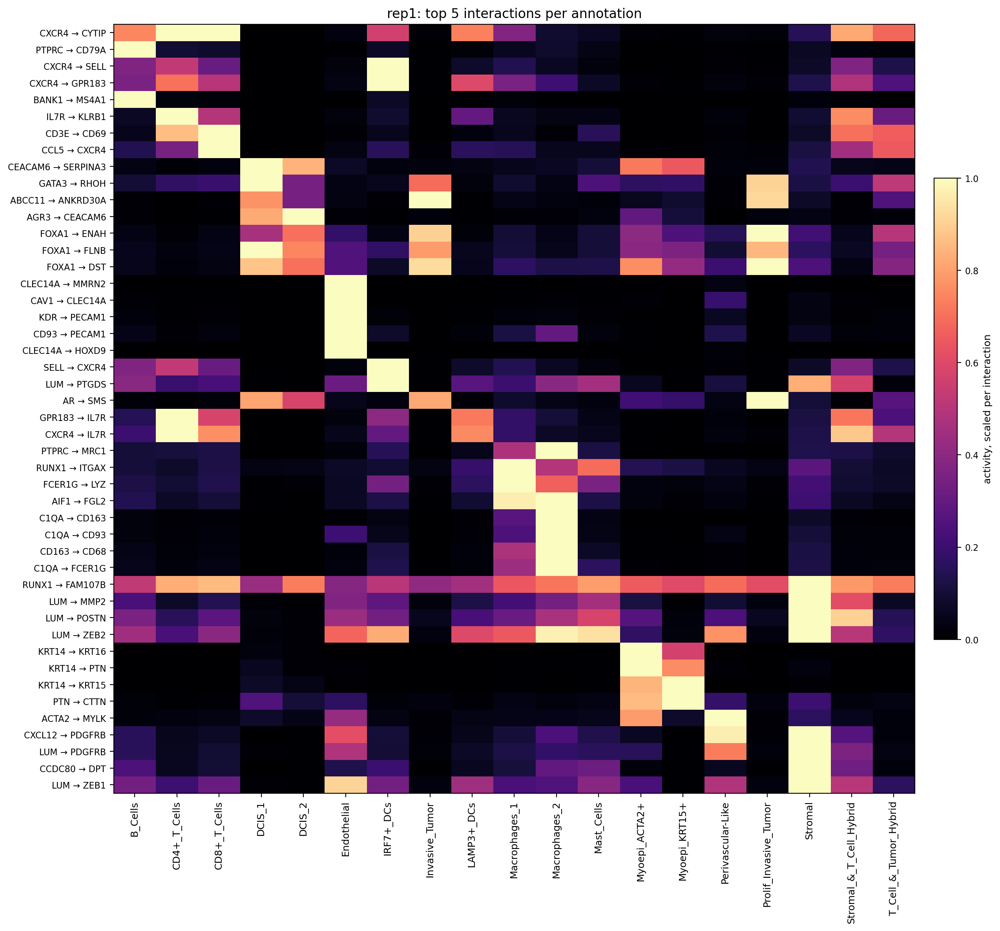

In [53]:
display(Image(filename=str(RESULTS_DIR / f"grn_top5_{LABEL}.png")))

### Cell-cell communication

Ligand-receptor communication between the same groups, scored as
attention times ligand expression in the sender times receptor expression
in the receiver.

The full table is exported unfiltered, one sheet per section, so
downstream analyses see everything. The chord diagram is filtered for
legibility: with 12 niches there are 132 possible directed links, and
drawing them all produces an unreadable figure. Three filters apply to
the figure only, and not to the exported table: saturated edges are
dropped, links below 15% of the strongest are removed, and the top 18 are
kept.

Saturated edges are worth understanding. Attention is normalised over
each target's incoming edges, so a receptor with a single regulator gets
an attention of exactly 1.0 by construction. Its score is then purely
expression-driven and carries no learned signal.

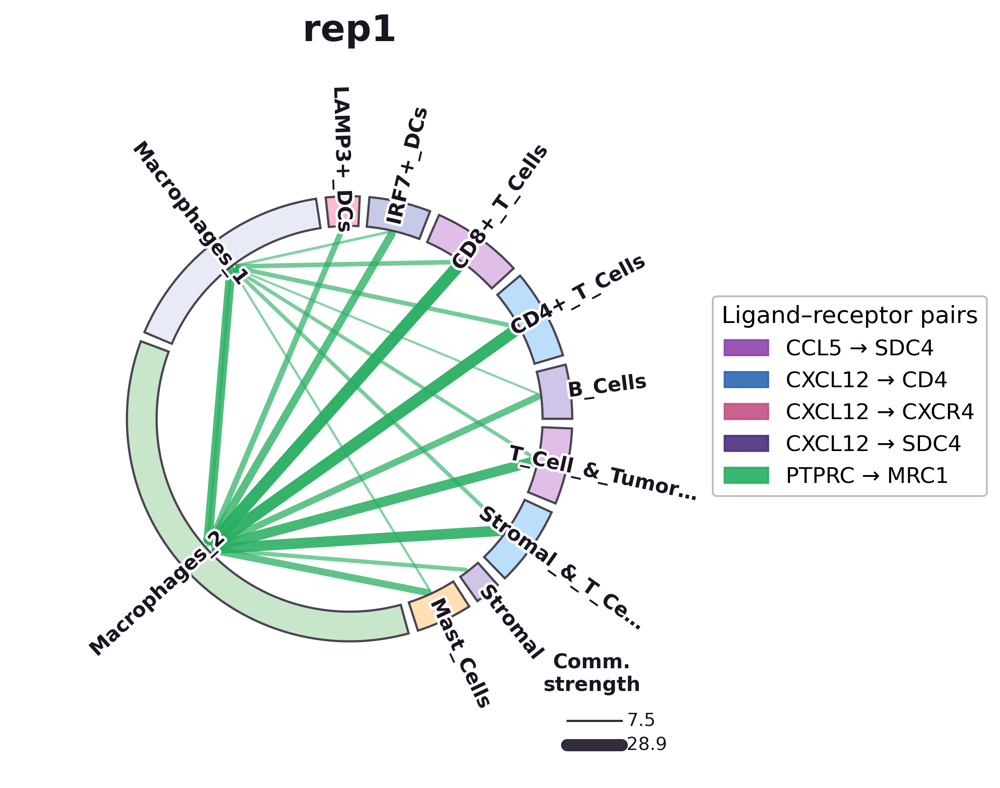

In [54]:
display(Image(filename=str(RESULTS_DIR / "ccc_chord.png")))

On a 313-gene panel a large share of the table is likely to be saturated,
and that is worth checking rather than assuming: it means the
gene-interaction graph has many receptors with only one regulator, so
those interactions are scored on expression alone. A larger panel, or a
lower co-expression threshold, gives receptors more competing regulators
and makes the attention more informative. If almost everything is
saturated, report the expression-driven scores as what they are.

## 8. Applying this to your own section

The steps are the same. Five things change.

**The annotation column.** `cell_type_key` and `niche_key` name columns
in your `obs`. Set `ANNOTATION = None` if your data is unannotated:
everything still runs, and FIDE is reported instead of ARI and NMI.

**`k`.** Run the diagnostic in section 3 on your own section. The reach
in cell diameters is what transfers between datasets, not the value of
`k` itself.

**The counts layer.** Nothing is passed here, because Xenium exports keep
counts in `X`. Where a file keeps them in a layer, name it; preprocessing
prints the available layers if the name is wrong, and prints what it
found if you pass nothing.

**Cluster and niche counts.** Set from what you expect to resolve. Stage
two is cheap, so try several.

**Species.** Affects both gene harmonisation and which curated priors the
GRN step retrieves.

One thing that does not change. The `.pt` file fixes which cells exist
and in what order, so the AnnData passed in must contain the same cells.
The pipeline checks this by coordinate and stops if they disagree, which
is why cell filtering is off by default at this stage.

### When you have a second section

Replicate 2 of this sample, or any other slide you want to compare
against this one, does not go through this notebook a second time. Two
separate runs give two sets of labels that share numbers and nothing
else. Encode them together instead, so they share one set of prototypes
and one clustering; notebook 03 does exactly that over three sections,
and the only change is a longer `SECTIONS` list.

### The same run from the command line

```bash
hebi-preprocess \
  --h5ad xenium_breast_cancer_rep1.h5ad --out_root processed/ \
  --vocab_path default_gene_vocab.json \
  --k 30 --species Human

hebi-run --config configs/breast_rep1.yaml --grn --grn_ccc
```

Putting the settings in a YAML file rather than passing flags keeps a
record of what produced a given set of results.